# Analyse churn - EcoPrime Banque

Notebook de travail pour le projet Analyse de Donnees (bloc 2). On reprend ici
les memes etapes que les scripts du dossier `src/` mais en version notebook,
avec les graphiques affiches directement et quelques commentaires au fil de
l'eau.

Le dataset est simule (voir la premiere section) : on n'a pas eu le jeu de
donnees de reference de l'ecole a temps, donc on a construit un portefeuille
client fictif pour une banque, EcoPrime Banque, avec un churn (resiliation)
comme variable cible. Le detail du raisonnement est dans `rapport.md`, ici on
se concentre sur le code et les resultats.

Sommaire :
1. Generation / chargement des donnees
2. Preparation (typage, valeurs manquantes, aberrantes)
3. Analyse univariee
4. Analyse bivariee (correlations, chi2, t-test/ANOVA)
5. ACP
6. Modelisation (regression logistique, arbre, random forest)
7. Evaluation + ecoresponsabilite
8. Partie 2 - marches financiers (Tesla / Stellantis)
9. Partie 3 - prototype IA generative


In [1]:
import sys
from pathlib import Path

RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(RACINE / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", 30)
plt.rcParams["figure.autolayout"] = True
sns.set_style("whitegrid")

RACINE


WindowsPath('c:/Cour master/projet fin année/Projet 1')

## 1. Generation / chargement des donnees

On reutilise `generation_donnees.py` pour reproduire exactement le meme
jeu de donnees que celui utilise dans le rapport (seed fixe, 2200 clients).
Si le fichier existe deja dans `data/`, on aurait pu simplement le charger,
mais on prefere regenerer ici pour que le notebook tourne tout seul, sans
dependre d'un fichier externe deja present.


In [2]:
from generation_donnees import generer

df_brut = generer()
print(df_brut.shape)
df_brut.head()


(2200, 23)


,id_client,age,sexe,situation_familiale,region,anciennete_mois,type_compte,nombre_produits,carte_credit,membre_actif,score_credit,salaire_annuel_net,solde_moyen_compte,montant_moyen_transaction,nb_transactions_mois,utilise_appli_mobile,nb_connexions_appli_mois,jours_depuis_derniere_connexion,nb_reclamations_12mois,score_satisfaction,canal_contact_prefere,date_dernier_contact,churn
0,100000,46,M,NaN,Grand Est,106,Professionnel,2,Non,Oui,604.0,49656.07,1064.52,54.07,14,Oui,3,27,1,4.0,Email,2025-07-30,Non
1,100001,53,M,Marie,PACA,54,Premium,2,Oui,Non,598.0,56581.28,5303.79,72.36,13,Oui,14,37,0,3.0,SMS,2024-06-17,Non
2,100002,52,M,Celibataire,Bretagne,55,Courant,2,Oui,Non,670.0,35709.89,7438.85,74.83,15,Oui,8,77,3,2.0,Agence,2024-03-14,Oui
3,100003,35,F,Divorce,PACA,21,Courant,1,Oui,Oui,633.0,28927.98,5065.72,21.24,19,Oui,12,113,1,5.0,Email,2025-06-08,Non
4,100004,39,M,Marie,PACA,53,Professionnel,1,Oui,Oui,539.0,50824.98,4600.77,39.98,13,Oui,16,28,0,3.0,Agence,2025-07-26,Oui


## 2. Preparation des donnees (C3.1)

Typage informatique + statistique, reperage des valeurs manquantes et des
valeurs aberrantes (methode IQR pour les continues, bornes metier pour l'age).


In [3]:
df = df_brut.copy()
df["date_dernier_contact"] = pd.to_datetime(df["date_dernier_contact"])

for c in ["sexe", "situation_familiale", "region", "type_compte", "canal_contact_prefere"]:
    df[c] = df[c].astype("category")
for c in ["carte_credit", "membre_actif", "utilise_appli_mobile", "churn"]:
    df[c] = df[c].map({"Oui": 1, "Non": 0}).astype("Int64")

manquants = df.isna().sum()
manquants = manquants[manquants > 0]
print("valeurs manquantes :")
manquants


valeurs manquantes :


situation_familiale      22
score_credit             66
salaire_annuel_net       55
score_satisfaction       33
canal_contact_prefere    44
dtype: int64

In [4]:
def bornes_iqr(serie, k=3.0):
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

# imputation simple, documentee dans le rapport (mediane / modalite "Inconnu")
df["score_credit"] = df["score_credit"].fillna(df["score_credit"].median())
df["salaire_annuel_net"] = df["salaire_annuel_net"].fillna(df["salaire_annuel_net"].median())
df["score_satisfaction"] = df["score_satisfaction"].fillna(df["score_satisfaction"].median())
df["canal_contact_prefere"] = df["canal_contact_prefere"].cat.add_categories(["Inconnu"]).fillna("Inconnu")
df["situation_familiale"] = df["situation_familiale"].cat.add_categories(["Inconnu"]).fillna("Inconnu")

df["age"] = df["age"].clip(upper=100)

colonnes_continues = ["score_credit", "salaire_annuel_net", "solde_moyen_compte", "montant_moyen_transaction"]
for col in colonnes_continues:
    basse, haute = bornes_iqr(df[col])
    nb_hors = ((df[col] < basse) | (df[col] > haute)).sum()
    print(f"{col} : {nb_hors} valeur(s) hors [{basse:.1f}, {haute:.1f}] -> plafonnees")
    df[col] = df[col].clip(lower=basse, upper=haute)

print("\nplus de valeurs manquantes :", df.isna().sum().sum())
df.describe(include="all").T.head(10)


score_credit : 0 valeur(s) hors [313.0, 845.0] -> plafonnees
salaire_annuel_net : 4 valeur(s) hors [-16011.6, 91373.0] -> plafonnees
solde_moyen_compte : 4 valeur(s) hors [-9568.5, 17901.1] -> plafonnees
montant_moyen_transaction : 0 valeur(s) hors [-40.9, 136.3] -> plafonnees

plus de valeurs manquantes : 0


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
id_client,2200.0,NaN,NaN,NaN,101099.5,100000.0,100549.75,101099.5,101649.25,102199.0,635.229617
age,2200.0,NaN,NaN,NaN,42.100909,18.0,33.0,42.0,51.0,100.0,12.818238
sexe,2200,2,M,1103,NaN,NaN,NaN,NaN,NaN,NaN,NaN
situation_familiale,2200,5,Marie,936,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,2200,10,Ile-de-France,502,NaN,NaN,NaN,NaN,NaN,NaN,NaN
anciennete_mois,2200.0,NaN,NaN,NaN,63.282727,1.0,32.0,55.0,84.0,349.0,42.143706
type_compte,2200,3,Courant,1499,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nombre_produits,2200.0,NaN,NaN,NaN,2.064545,1.0,1.0,2.0,3.0,4.0,0.930225
carte_credit,2200.0,<NA>,<NA>,<NA>,0.710909,0.0,0.0,1.0,1.0,1.0,0.453443
membre_actif,2200.0,<NA>,<NA>,<NA>,0.62,0.0,0.0,1.0,1.0,1.0,0.485497


## 3. Analyse univariee (C3.3)

On regarde chaque variable toute seule : distribution pour les
quantitatives, frequences pour les qualitatives.


In [5]:
VAR_QUANTI = [
    "age", "anciennete_mois", "nombre_produits", "score_credit",
    "salaire_annuel_net", "solde_moyen_compte", "montant_moyen_transaction",
    "nb_transactions_mois", "nb_connexions_appli_mois",
    "jours_depuis_derniere_connexion", "nb_reclamations_12mois",
]
VAR_QUALI = [
    "sexe", "situation_familiale", "region", "type_compte", "carte_credit",
    "membre_actif", "utilise_appli_mobile", "score_satisfaction",
    "canal_contact_prefere", "churn",
]

df[VAR_QUANTI].describe().T[["mean", "50%", "std", "25%", "75%", "min", "max"]].rename(columns={"50%": "mediane"})


,mean,mediane,std,25%,75%,min,max
age,42.100909,42.000,12.818238,33.0000,51.000,18.000,100.0000
anciennete_mois,63.282727,55.000,42.143706,32.0000,84.000,1.000,349.0000
nombre_produits,2.064545,2.000,0.930225,1.0000,3.000,1.000,4.0000
score_credit,580.005455,581.000,57.398600,541.0000,617.000,394.000,771.0000
salaire_annuel_net,37959.674114,37144.640,11802.321891,30010.3525,45351.015,9500.000,91373.0025
solde_moyen_compte,4300.354609,4047.470,2853.491735,2204.1525,6128.385,-9568.545,15340.8200
montant_moyen_transaction,47.692209,47.665,18.418302,35.0350,60.355,5.000,104.8300
nb_transactions_mois,14.032727,14.000,3.733849,11.0000,17.000,4.000,29.0000
nb_connexions_appli_mois,6.824545,7.000,4.573699,2.0000,10.000,0.000,21.0000
jours_depuis_derniere_connexion,18.250000,12.000,18.543589,5.0000,25.000,0.000,152.0000


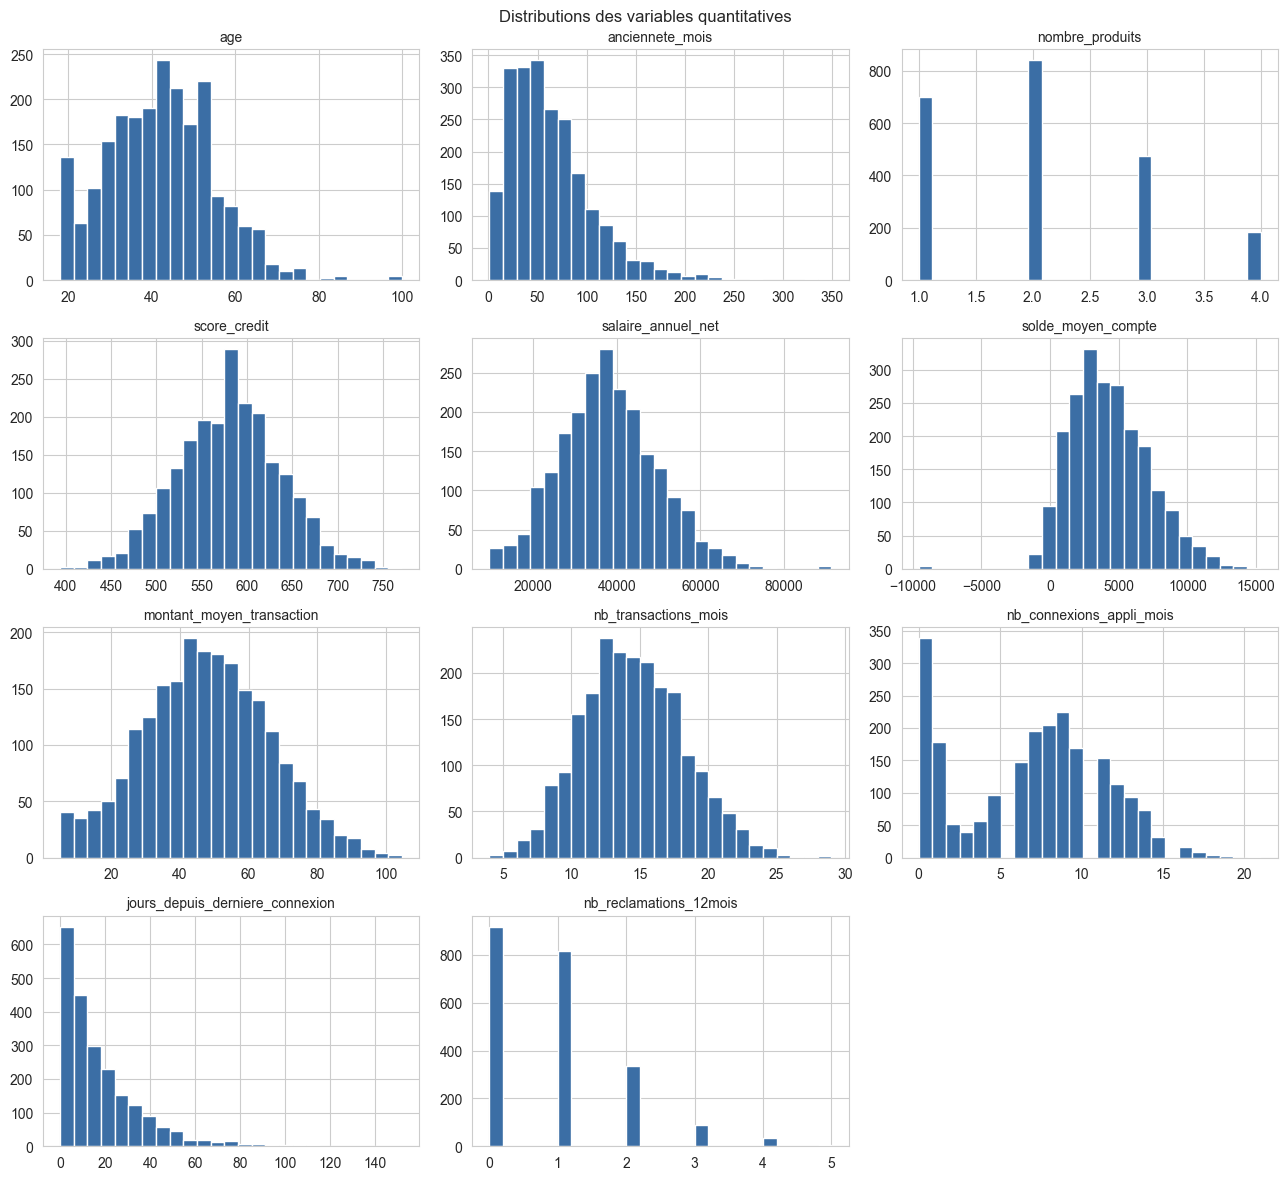

In [6]:
fig, axes = plt.subplots(4, 3, figsize=(13, 12))
for ax, col in zip(axes.ravel(), VAR_QUANTI):
    ax.hist(df[col], bins=25, color="#3b6ea5", edgecolor="white")
    ax.set_title(col, fontsize=10)
axes.ravel()[-1].axis("off")
fig.suptitle("Distributions des variables quantitatives")
plt.show()



type_compte :
  Courant : 1499 (68.1%)
  Premium : 473 (21.5%)
  Professionnel : 228 (10.4%)

score_satisfaction :
  4.0 : 840 (38.2%)
  3.0 : 609 (27.7%)
  5.0 : 469 (21.3%)
  2.0 : 236 (10.7%)
  1.0 : 46 (2.1%)

churn :
  0 : 1679 (76.3%)
  1 : 521 (23.7%)


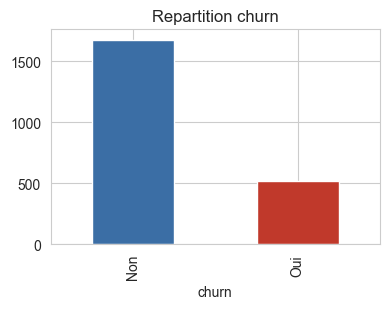

In [7]:
for col in ["type_compte", "score_satisfaction", "churn"]:
    freq = df[col].value_counts(dropna=False)
    pct = (freq / len(df) * 100).round(1)
    print(f"\n{col} :")
    for modalite, effectif in freq.items():
        print(f"  {modalite} : {effectif} ({pct[modalite]}%)")

fig, ax = plt.subplots(figsize=(4, 3.2))
df["churn"].map({0: "Non", 1: "Oui"}).value_counts().plot(kind="bar", ax=ax, color=["#3b6ea5", "#c0392b"])
ax.set_title("Repartition churn")
plt.show()


## 4. Analyse bivariee (C3.3)

Correlations entre quantitatives, puis lien de chaque variable avec le
churn (Chi2 pour les qualitatives, t-test pour les quantitatives).


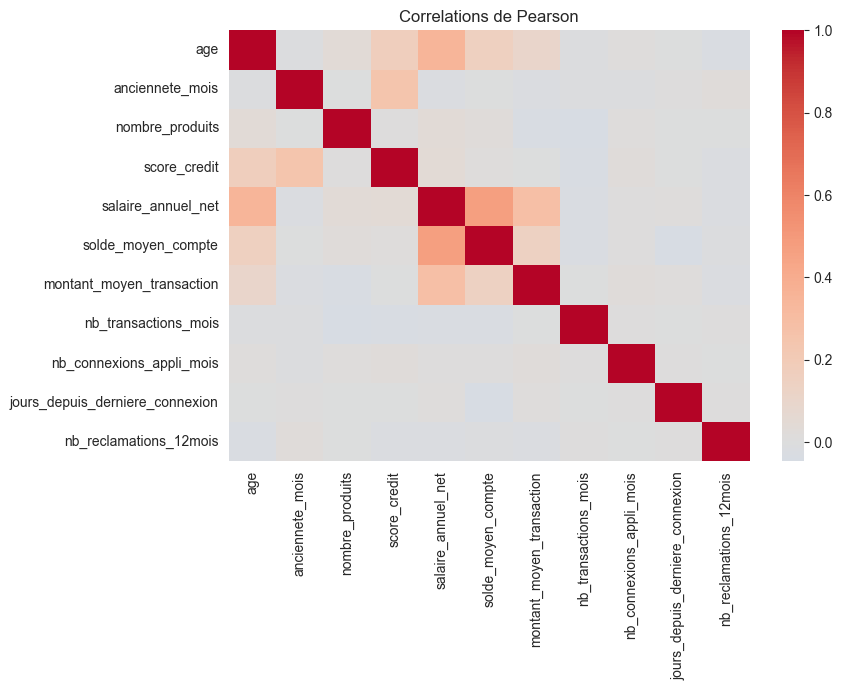

paires les plus correlees :
  salaire_annuel_net / solde_moyen_compte : r = 0.473
  salaire_annuel_net / age : r = 0.347
  salaire_annuel_net / montant_moyen_transaction : r = 0.284
  anciennete_mois / score_credit : r = 0.251
  age / score_credit : r = 0.172


In [8]:
corr = df[VAR_QUANTI].corr(method="pearson")

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False, ax=ax)
ax.set_title("Correlations de Pearson")
plt.show()

paires = corr.where(~np.eye(len(VAR_QUANTI), dtype=bool)).abs().unstack().sort_values(ascending=False)
paires = paires[~paires.duplicated()].head(5)
print("paires les plus correlees :")
for (a, b), v in paires.items():
    print(f"  {a} / {b} : r = {corr.loc[a, b]:.3f}")


In [9]:
VAR_QUALI_TEST = ["sexe", "situation_familiale", "region", "type_compte", "carte_credit", "membre_actif", "utilise_appli_mobile", "canal_contact_prefere"]

print("Chi2 (variable qualitative vs churn) :")
for col in VAR_QUALI_TEST:
    table = pd.crosstab(df[col], df["churn"])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    signif = "significatif" if p < 0.05 else "non significatif"
    print(f"  {col:22s} chi2={chi2:6.2f}  ddl={dof}  p={p:.4f}  -> {signif}")


Chi2 (variable qualitative vs churn) :
  sexe                   chi2=  0.87  ddl=1  p=0.3515  -> non significatif
  situation_familiale    chi2=  3.67  ddl=4  p=0.4520  -> non significatif
  region                 chi2= 12.82  ddl=9  p=0.1711  -> non significatif
  type_compte            chi2=  3.78  ddl=2  p=0.1511  -> non significatif
  carte_credit           chi2=  0.05  ddl=1  p=0.8149  -> non significatif
  membre_actif           chi2=  4.05  ddl=1  p=0.0442  -> significatif
  utilise_appli_mobile   chi2=  0.85  ddl=1  p=0.3559  -> non significatif
  canal_contact_prefere  chi2=  4.80  ddl=4  p=0.3080  -> non significatif


t-test (variable quantitative vs churn) :
  age                              moy(Oui)=   42.09  moy(Non)=   42.10  t= -0.02  p=0.9857  -> non significatif
  anciennete_mois                  moy(Oui)=   53.92  moy(Non)=   66.19  t= -6.64  p=0.0000  -> significatif
  nombre_produits                  moy(Oui)=    1.95  moy(Non)=    2.10  t= -3.45  p=0.0006  -> significatif
  score_credit                     moy(Oui)=  579.14  moy(Non)=  580.27  t= -0.40  p=0.6922  -> non significatif
  salaire_annuel_net               moy(Oui)=37619.49  moy(Non)=38065.24  t= -0.77  p=0.4404  -> non significatif
  solde_moyen_compte               moy(Oui)= 4261.52  moy(Non)= 4312.40  t= -0.36  p=0.7208  -> non significatif
  montant_moyen_transaction        moy(Oui)=   47.46  moy(Non)=   47.76  t= -0.33  p=0.7449  -> non significatif
  nb_transactions_mois             moy(Oui)=   14.15  moy(Non)=   14.00  t=  0.82  p=0.4105  -> non significatif
  nb_connexions_appli_mois         moy(Oui)=    6.75  moy(Non)

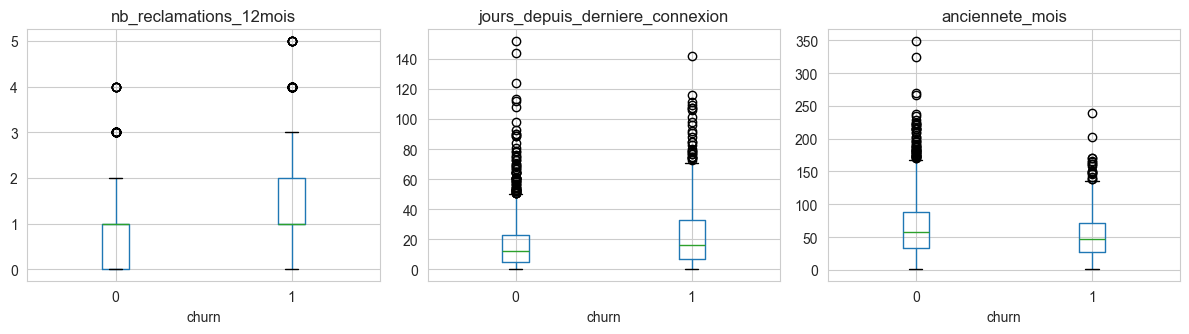

In [10]:
print("t-test (variable quantitative vs churn) :")
for col in VAR_QUANTI:
    grp_oui = df.loc[df["churn"] == 1, col].dropna()
    grp_non = df.loc[df["churn"] == 0, col].dropna()
    t, p = stats.ttest_ind(grp_oui, grp_non, equal_var=False)
    signif = "significatif" if p < 0.05 else "non significatif"
    print(f"  {col:32s} moy(Oui)={grp_oui.mean():8.2f}  moy(Non)={grp_non.mean():8.2f}  t={t:6.2f}  p={p:.4f}  -> {signif}")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, col in zip(axes, ["nb_reclamations_12mois", "jours_depuis_derniere_connexion", "anciennete_mois"]):
    df.boxplot(column=col, by="churn", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("churn")
plt.suptitle("")
plt.show()


## 5. ACP

Standardisation des variables quantitatives puis ACP complete, pour voir
combien d'axes il faut pour capter l'essentiel de la variance.


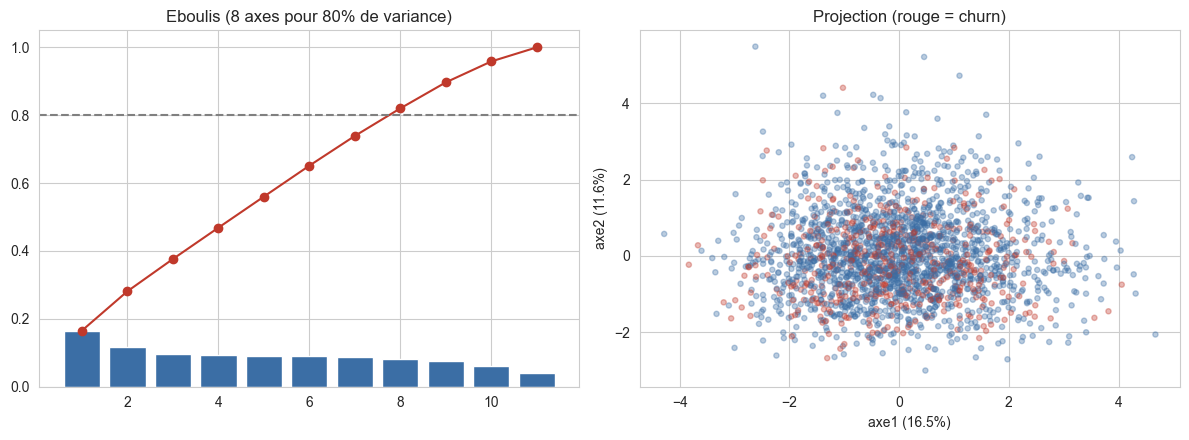

,axe1,axe2
salaire_annuel_net,0.620912,-0.097830
solde_moyen_compte,0.511471,-0.130273
age,0.438630,0.165783
montant_moyen_transaction,0.362795,-0.173589
score_credit,0.141798,0.693843
nb_transactions_mois,-0.051093,-0.094467
nombre_produits,0.050175,0.043461
nb_reclamations_12mois,-0.042536,0.005618
nb_connexions_appli_mois,0.036437,0.031408
anciennete_mois,0.017559,0.650043


In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X_acp = df[VAR_QUANTI]
X_acp_std = StandardScaler().fit_transform(X_acp)

acp = PCA(n_components=len(VAR_QUANTI))
composantes = acp.fit_transform(X_acp_std)
variance_expliquee = acp.explained_variance_ratio_
variance_cumulee = np.cumsum(variance_expliquee)
nb_axes_80 = np.argmax(variance_cumulee >= 0.8) + 1

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(range(1, len(variance_expliquee) + 1), variance_expliquee, color="#3b6ea5")
axes[0].plot(range(1, len(variance_expliquee) + 1), variance_cumulee, color="#c0392b", marker="o")
axes[0].axhline(0.8, color="grey", linestyle="--")
axes[0].set_title(f"Eboulis ({nb_axes_80} axes pour 80% de variance)")

couleurs = np.where(df["churn"] == 1, "#c0392b", "#3b6ea5")
axes[1].scatter(composantes[:, 0], composantes[:, 1], c=couleurs, alpha=0.35, s=14)
axes[1].set_xlabel(f"axe1 ({variance_expliquee[0]*100:.1f}%)")
axes[1].set_ylabel(f"axe2 ({variance_expliquee[1]*100:.1f}%)")
axes[1].set_title("Projection (rouge = churn)")
plt.show()

loadings = pd.DataFrame(acp.components_[:2].T, index=VAR_QUANTI, columns=["axe1", "axe2"])
loadings.sort_values("axe1", key=abs, ascending=False)


## 6. Modelisation predictive (C4.2) et evaluation (C4.3)

Trois modeles : regression logistique, arbre de decision, random forest.
On regarde l'AUC (train et test, pour reperer le sur-apprentissage), le F1,
la precision, le rappel, et un proxy tres simple d'ecoresponsabilite (temps
d'entrainement).


In [12]:
import time
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score, roc_curve

VAR_QUALI_BIN = ["carte_credit", "membre_actif", "utilise_appli_mobile"]
VAR_QUALI_NOM = ["sexe", "situation_familiale", "region", "type_compte", "canal_contact_prefere"]

X = pd.concat([
    df[VAR_QUANTI + ["score_satisfaction"] + VAR_QUALI_BIN],
    pd.get_dummies(df[VAR_QUALI_NOM], drop_first=True),
], axis=1)
y = df["churn"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=1742, stratify=y)
scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
X_test_std = scaler.transform(X_test)

modeles = {
    "regression_logistique": (LogisticRegression(max_iter=2000, class_weight="balanced"), X_train_std, X_test_std),
    "arbre_de_decision": (DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=1742), X_train, X_test),
    "random_forest": (RandomForestClassifier(n_estimators=200, max_depth=8, class_weight="balanced", random_state=1742, n_jobs=-1), X_train, X_test),
}

resultats = {}
courbes_roc = {}
for nom, (modele, xtr, xte) in modeles.items():
    t0 = time.perf_counter()
    modele.fit(xtr, y_train)
    duree = time.perf_counter() - t0
    proba_test = modele.predict_proba(xte)[:, 1]
    proba_train = modele.predict_proba(xtr)[:, 1]
    pred_test = modele.predict(xte)
    resultats[nom] = {
        "auc_test": roc_auc_score(y_test, proba_test),
        "auc_train": roc_auc_score(y_train, proba_train),
        "f1": f1_score(y_test, pred_test),
        "precision": precision_score(y_test, pred_test),
        "rappel": recall_score(y_test, pred_test),
        "temps_s": duree,
    }
    courbes_roc[nom] = roc_curve(y_test, proba_test)

tableau_resultats = pd.DataFrame(resultats).T
tableau_resultats["ecart_train_test"] = tableau_resultats["auc_train"] - tableau_resultats["auc_test"]
tableau_resultats.round(4)


,auc_test,auc_train,f1,precision,rappel,temps_s,ecart_train_test
regression_logistique,0.8134,0.8413,0.5613,0.4833,0.6692,0.0092,0.0279
arbre_de_decision,0.7676,0.8477,0.5252,0.4932,0.5615,0.0101,0.0801
random_forest,0.8201,0.9741,0.5556,0.6250,0.5000,0.3681,0.1539


Petite variation possible sur la random forest par rapport aux chiffres cites
dans `rapport.md` (elle etait entrainee separement via le script, ici dans le
notebook) : rien d'anormal, c'est le meme ordre de grandeur et la meme
conclusion (regression logistique = meilleur compromis performance / stabilite
/ cout d'entrainement).


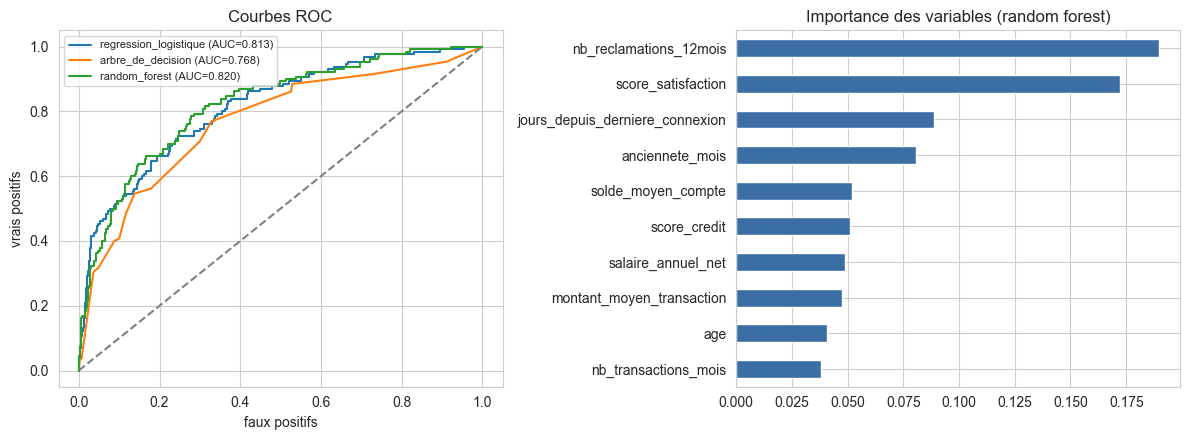

AUC en validation croisee (5 blocs) : moyenne=0.8163, ecart-type=0.0091


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for nom, (fpr, tpr, _) in courbes_roc.items():
    axes[0].plot(fpr, tpr, label=f"{nom} (AUC={resultats[nom]['auc_test']:.3f})")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="grey")
axes[0].set_xlabel("faux positifs"); axes[0].set_ylabel("vrais positifs")
axes[0].set_title("Courbes ROC")
axes[0].legend(fontsize=8)

foret = modeles["random_forest"][0]
importances = pd.Series(foret.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
importances.sort_values().plot(kind="barh", ax=axes[1], color="#3b6ea5")
axes[1].set_title("Importance des variables (random forest)")
plt.show()

# validation croisee sur la regression logistique, pour verifier la stabilite
scores_cv = cross_val_score(
    LogisticRegression(max_iter=2000, class_weight="balanced"),
    StandardScaler().fit_transform(X), y, cv=5, scoring="roc_auc"
)
print(f"AUC en validation croisee (5 blocs) : moyenne={scores_cv.mean():.4f}, ecart-type={scores_cv.std():.4f}")


## 7. Partie 2 - marches financiers (Tesla / Stellantis)

Cotations en direct via `yfinance` (necessite une connexion internet).


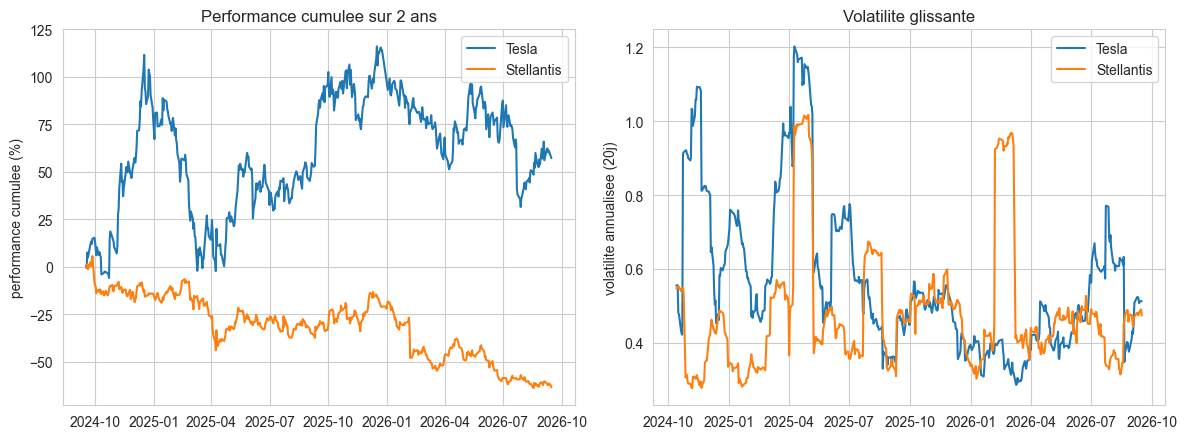

performance cumulee sur la periode :
  Tesla : 57.2%
  Stellantis : -63.4%


In [14]:
import yfinance as yf

cotations = {}
for ticker, nom in {"TSLA": "Tesla", "STLA": "Stellantis"}.items():
    d = yf.download(ticker, period="2y", auto_adjust=True, progress=False)
    cloture = d["Close"].squeeze()
    cloture.name = nom
    cotations[nom] = cloture
cotes = pd.concat(cotations.values(), axis=1)
cotes.columns = list(cotations.keys())

rendements = cotes.pct_change().dropna()
volatilite_20j = rendements.rolling(20).std() * np.sqrt(252)
perf_cumulee = (1 + rendements).cumprod() - 1

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for col in perf_cumulee.columns:
    axes[0].plot(perf_cumulee.index, perf_cumulee[col] * 100, label=col)
axes[0].set_ylabel("performance cumulee (%)"); axes[0].set_title("Performance cumulee sur 2 ans"); axes[0].legend()
for col in volatilite_20j.columns:
    axes[1].plot(volatilite_20j.index, volatilite_20j[col], label=col)
axes[1].set_ylabel("volatilite annualisee (20j)"); axes[1].set_title("Volatilite glissante"); axes[1].legend()
plt.show()

print("performance cumulee sur la periode :")
for col in cotes.columns:
    print(f"  {col} : {perf_cumulee[col].iloc[-1]*100:.1f}%")


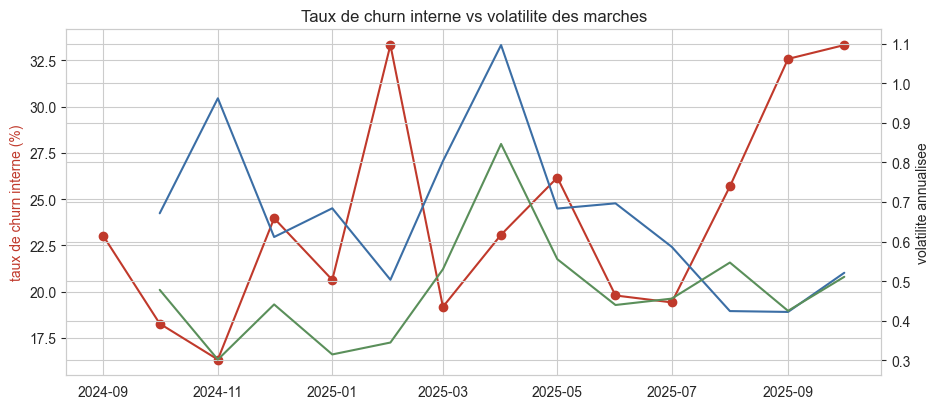

correlation mensuelle taux de churn / volatilite :
Tesla        -0.607
Stellantis    0.047
Name: taux_churn, dtype: float64

a prendre avec beaucoup de prudence : peu de points mensuels, et le jeu de
donnees clients est simule, sans lien reel avec la bourse.


In [15]:
df["mois"] = df["date_dernier_contact"].dt.to_period("M").dt.to_timestamp()
taux_churn_mensuel = df.groupby("mois")["churn"].mean().rename("taux_churn")
volat_mensuelle = volatilite_20j.resample("MS").mean()
jointure = volat_mensuelle.join(taux_churn_mensuel, how="inner")

fig, ax1 = plt.subplots(figsize=(9.5, 4.2))
ax1.plot(jointure.index, jointure["taux_churn"] * 100, color="#c0392b", marker="o", label="taux de churn interne (%)")
ax1.set_ylabel("taux de churn interne (%)", color="#c0392b")
ax2 = ax1.twinx()
ax2.plot(jointure.index, jointure["Tesla"], color="#3b6ea5", label="volatilite Tesla")
ax2.plot(jointure.index, jointure["Stellantis"], color="#5a8f5a", label="volatilite Stellantis")
ax2.set_ylabel("volatilite annualisee")
ax1.set_title("Taux de churn interne vs volatilite des marches")
plt.show()

correlation = jointure.corr(numeric_only=True)["taux_churn"].drop("taux_churn")
print("correlation mensuelle taux de churn / volatilite :")
print(correlation.round(3))
print("\na prendre avec beaucoup de prudence : peu de points mensuels, et le jeu de")
print("donnees clients est simule, sans lien reel avec la bourse.")


## 8. Partie 3 (facultative) - prototype IA generative

Generateur a base de gabarits (pas d'appel API dans cette version, voir
`rapport.md` pour la justification). On applique ca aux 5 clients qui ont
le plus de reclamations, comme exemple de clients "a risque".


In [16]:
def choisir_raison(client):
    if client["nb_reclamations_12mois"] >= 2:
        return "plusieurs reclamations recentes"
    if client["jours_depuis_derniere_connexion"] >= 30:
        return "une baisse d'activite sur les derniers mois"
    return "un client encore recent, periode ou le risque de depart est plus eleve"


def generer_message(client):
    raison = choisir_raison(client)
    civilite = "Madame" if client["sexe"] == "F" else "Monsieur"
    if client["nombre_produits"] <= 1:
        action = "un point telephonique pour revoir son offre et lui presenter les produits complementaires adaptes"
    else:
        action = "un rendez-vous en agence pour faire le point sur sa satisfaction et ses besoins actuels"
    return (
        f"{civilite}, client depuis {client['anciennete_mois']} mois (compte {client['type_compte'].lower()}), "
        f"presente un risque de resiliation lie a {raison}. "
        f"Action recommandee : proposer {action}. "
        f"Canal de contact prefere : {client['canal_contact_prefere']}."
    )


clients_a_risque = df.sort_values("nb_reclamations_12mois", ascending=False).head(5)
for _, client in clients_a_risque.iterrows():
    print(f"- {generer_message(client)}\n")


- Monsieur, client depuis 78 mois (compte courant), presente un risque de resiliation lie a plusieurs reclamations recentes. Action recommandee : proposer un point telephonique pour revoir son offre et lui presenter les produits complementaires adaptes. Canal de contact prefere : Agence.

- Madame, client depuis 10 mois (compte courant), presente un risque de resiliation lie a plusieurs reclamations recentes. Action recommandee : proposer un point telephonique pour revoir son offre et lui presenter les produits complementaires adaptes. Canal de contact prefere : Email.

- Monsieur, client depuis 40 mois (compte courant), presente un risque de resiliation lie a plusieurs reclamations recentes. Action recommandee : proposer un point telephonique pour revoir son offre et lui presenter les produits complementaires adaptes. Canal de contact prefere : Appel.

- Madame, client depuis 96 mois (compte professionnel), presente un risque de resiliation lie a plusieurs reclamations recentes. Actio

## Conclusion (rapide)

Le signal de churn tient surtout a trois variables comportementales
(reclamations, inactivite recente, anciennete), pas au profil
socio-demographique. La regression logistique suffit largement et generalise
mieux que la random forest sur ce jeu de donnees, pour un cout de calcul
nettement plus faible. Le detail de l'argumentation, la strategie
d'integration de l'IA et les limites du projet sont dans `rapport.md`.
